# Try out

In [1]:
# import libraries
import os.path
import pickle
import torch
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import math
from PIL import Image

from sklearn.decomposition import PCA

# For processing single image to test
import clip
import torch
from sklearn.preprocessing import normalize

import torch.nn.functional as F

## t-SNE Scatter Plotting
----

In [2]:
def visualize_tsne_points(tx, ty, labels, class_names):
    print('Plotting TSNE image')
    # initialize matplotlib plot
    fig = plt.figure()
    ax = fig.add_subplot(111)

    colors_per_class = {
        0 : [254, 202, 87],
        1 : [255, 107, 107],
        2 : [10, 189, 227],
        3 : [255, 159, 243],
        4 : [16, 172, 132],
        5 : [128, 80, 128]
    }

    colors_per_class = {k: v for k,v in colors_per_class.items() if k in np.unique(labels)}
    
    # for every class, we'll add a scatter plot separately
    for label in colors_per_class:
        # find the samples of the current class in the data
        indices = [i for i, l in enumerate(labels) if l == label]
        # extract the coordinates of the points of this class only
        current_tx = np.take(tx, indices)
        current_ty = np.take(ty, indices)
        
        # convert the class color to matplotlib format:
        # BGR -> RGB, divide by 255, convert to np.array
        color = np.array([colors_per_class[label][::-1]], dtype=np.single) / 255
        
        # add a scatter plot with the correponding color and label
        ax.scatter(current_tx, current_ty, c=color, label=class_names[label])

        # build a legend using the labels we set previously
    ax.legend(bbox_to_anchor=(1.5, 1.))

    # finally, show the plot
    plt.show()
    # plt.savefig('visualize_tsne_points.png')

In [3]:
# scale and move the coordinates so they fit [0; 1] range
def scale_to_01_range(x):
    # compute the distribution range
    value_range = (np.max(x) - np.min(x))
 
    # move the distribution so that it starts from zero
    # by extracting the minimal value from all its values
    starts_from_zero = x - np.min(x)
 
    # make the distribution fit [0; 1] by dividing by its range
    return starts_from_zero / value_range

In [4]:
def get_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    # text_list_prompt = [f"This is a photo of {item}." for item in text_list]
    text_list_prompt = text_list
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).squeeze().detach().numpy()

(20000, 512)
(50, 512)
(20050, 512)
(20050,)
Plotting TSNE image


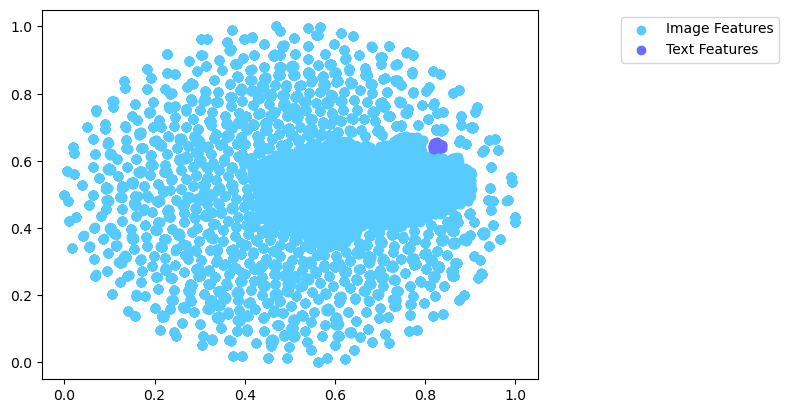

In [5]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_CelebA5k_furniture15k.pkl', 'rb') as f:
    img_features_CelebA5k_furniture15k = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_50_USER_CS.pkl', 'rb') as f:
    text_features_celebA_50_USER = pickle.load(f).cpu().numpy()

# combine image and text features to plot scatter plot
print(img_features_CelebA5k_furniture15k.shape)
print(text_features_celebA_50_USER.shape)
img_text_features = np.concatenate((img_features_CelebA5k_furniture15k, text_features_celebA_50_USER), axis=0)
img_text_features_labels = np.concatenate((np.zeros(img_features_CelebA5k_furniture15k.shape[0]), np.ones(text_features_celebA_50_USER.shape[0])), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)

# extract x and y coordinates representing the positions of the images on T-SNE plot
tsne = TSNE(n_components=2).fit_transform(img_text_features)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Image Features', 'Text Features'])

Plotting TSNE image


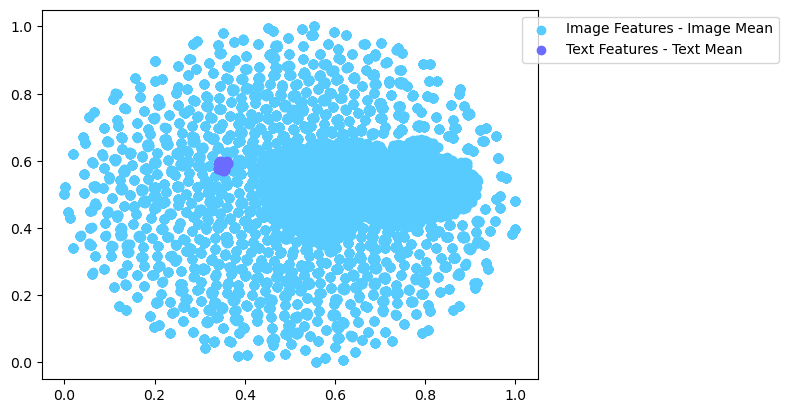

In [6]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_CelebA5k_furniture15k.pkl', 'rb') as f:
    img_features_CelebA5k_furniture15k = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_50_USER_CS.pkl', 'rb') as f:
    text_features_celebA_50_USER = pickle.load(f).cpu().numpy()
    
# subtraction of mean value
img_features_CelebA5k_furniture15k_minus_mean = img_features_CelebA5k_furniture15k - img_features_CelebA5k_furniture15k.mean(axis=0)
text_features_celebA_50_USER_minus_mean = text_features_celebA_50_USER - text_features_celebA_50_USER.mean(axis=0)
img_text_features = np.concatenate((img_features_CelebA5k_furniture15k_minus_mean, text_features_celebA_50_USER_minus_mean), axis=0)
img_text_features_labels = np.concatenate((np.zeros(img_features_CelebA5k_furniture15k_minus_mean.shape[0]), np.ones(text_features_celebA_50_USER_minus_mean.shape[0])), axis=0)

# extract x and y coordinates representing the positions of the images on T-SNE plot
tsne = TSNE(n_components=2).fit_transform(img_text_features)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Image Features - Image Mean', 'Text Features - Text Mean'])

## Single Image Test
-----

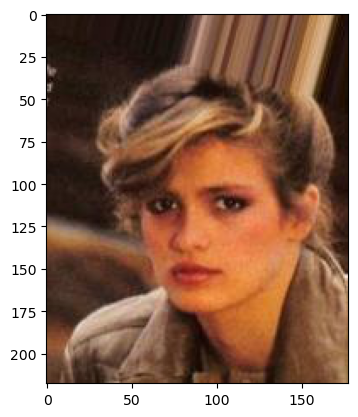

In [7]:
# The images for test
img_path = '/Users/yifanlu/Desktop/Datasets/CelebA_process/CelebA_5k/103998.jpg'
img = np.asarray(Image.open(img_path))
imgplot = plt.imshow(img)

In [8]:
# Read the image and text features
# original: CelebA5k+Furniture15k   test: Celeb5k
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

text_list = ['man', 'eyeglasses']

text_list_prompt = [f"This is a photo of {item}." for item in text_list]

image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)
text = clip.tokenize(text_list_prompt).to(device)

with torch.no_grad():
    logits_per_image, logits_per_text = model(image, text)

print("Label probs:", logits_per_image[0,0], logits_per_image[0,1])

Label probs: tensor(20.6443) tensor(21.8418)


In [9]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_woman.pkl', 'rb') as f:
    img_features_woman = pickle.load(f)

with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)

    img_features = image_features - img_features_man.mean(axis=0)
    text_features = text_features - text_features.mean(axis=0)
    img_features /= img_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)
    similarity = (100 * img_features @ text_features.T)

print("Label probs:", similarity[0,0], similarity[0,1])

Label probs: tensor(-11.7742) tensor(11.7742)


In [10]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo of {item}." if i == 0 else f"This is not a photo of {item}." for item in text_list for i in range(2)]
    # text_list_prompt = [f"{item}" if i == 0 else f"not {item}" for item in text_list for i in range(2)]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_woman.pkl', 'rb') as f:
    img_features_woman = pickle.load(f)

text_list = ['man', 'eyeglasses']
dual_text_features = get_dual_text_embedding(text_list)

# dual scores
img_features /= img_features.norm(dim=-1, keepdim=True)
dual_text_features /= dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ dual_text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, len(text_list), 2]), dim=2)
scores = 100 * cs_softmax
dual_scores = scores[:, :, 0]

print("Label probs:", dual_scores[0,0], dual_scores[0,1])

Label probs: tensor(49.3873) tensor(49.9811)


## Scatter Plot x:<I, T> y: <I-I_mean, T-T_mean>
--------

In [11]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

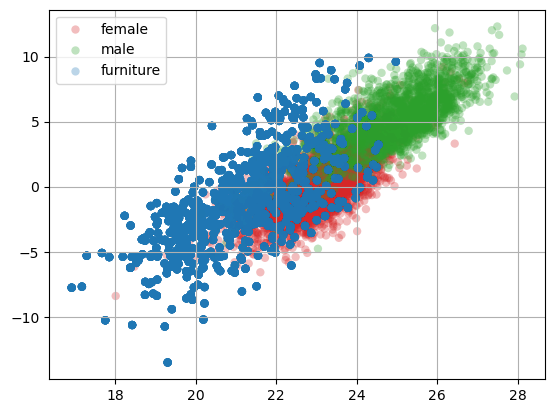

In [12]:
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 0]
y_0 = similarity_minus_mean[img_labels==0][:, 0]
x_1 = original_similarity[img_labels==1][:, 0]
y_1 = similarity_minus_mean[img_labels==1][:, 0]
x_2 = original_similarity[img_labels==2][:, 0]
y_2 = similarity_minus_mean[img_labels==2][:, 0]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='female')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='male')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

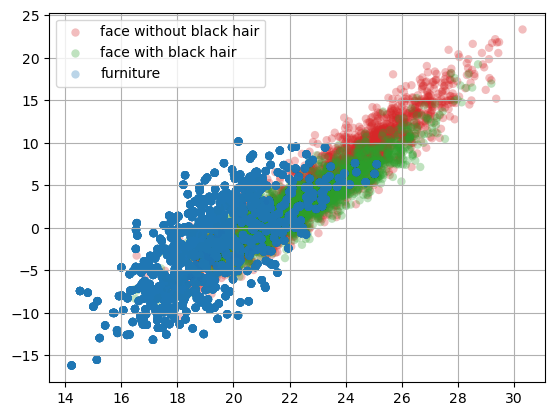

In [13]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 3]
y_0 = similarity_minus_mean[img_labels==0][:, 3]
x_1 = original_similarity[img_labels==1][:, 3]
y_1 = similarity_minus_mean[img_labels==1][:, 3]
x_2 = original_similarity[img_labels==2][:, 3]
y_2 = similarity_minus_mean[img_labels==2][:, 3]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without black hair')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with black hair')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

In [14]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'sir']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'sir']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features_man.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

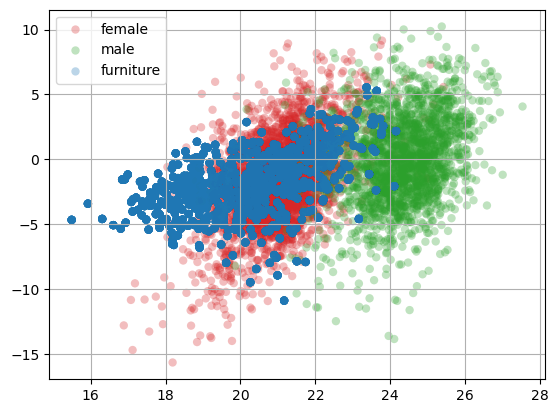

In [15]:
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 0]
y_0 = similarity_minus_mean[img_labels==0][:, 0]
x_1 = original_similarity[img_labels==1][:, 0]
y_1 = similarity_minus_mean[img_labels==1][:, 0]
x_2 = original_similarity[img_labels==2][:, 0]
y_2 = similarity_minus_mean[img_labels==2][:, 0]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='female')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='male')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

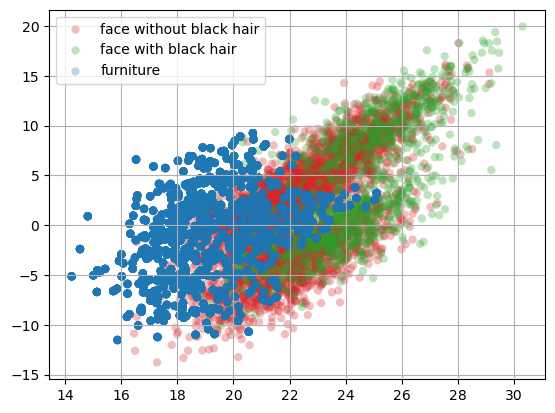

In [16]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_black_hair.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'black hair']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_black_hair.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'black hair']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = similarity_minus_mean[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = similarity_minus_mean[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = similarity_minus_mean[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without black hair')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with black hair')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

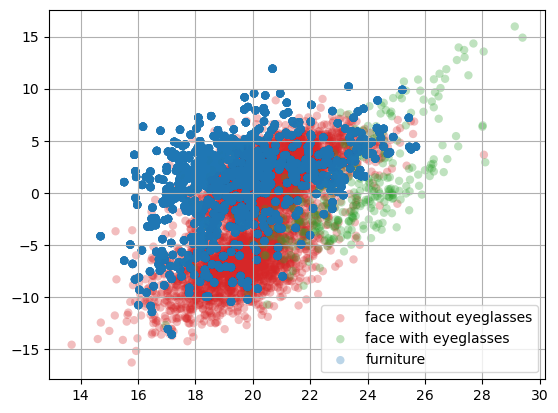

In [17]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'eyeglasses']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'eyeglasses']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = similarity_minus_mean[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = similarity_minus_mean[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = similarity_minus_mean[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without eyeglasses')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with eyeglasses')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

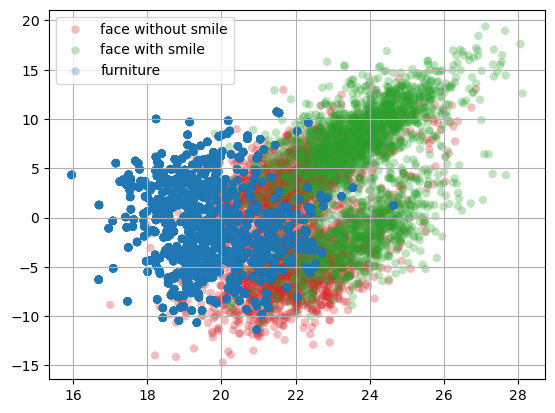

In [18]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_smiling.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'smile']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_smiling.pkl', 'rb') as f:
    img_labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    img_features_man = pickle.load(f)

text_list = ['man', 'smile']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

# <I-I_mean, T-T_mean>
img_features = img_features - img_features.mean(axis=0)
text_features = text_features - text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity_minus_mean = (100 * img_features @ text_features.T)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = similarity_minus_mean[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = similarity_minus_mean[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = similarity_minus_mean[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without smile')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with smile')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

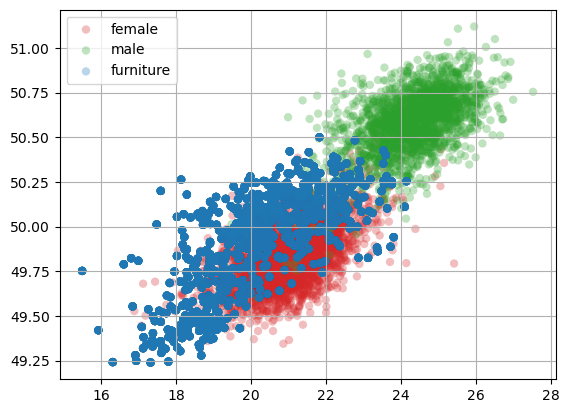

In [20]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo of {item}." if i == 0 else f"This is a photo without {item}." for item in text_list for i in range(2)]
    # text_list_prompt = [f"{item}" if i == 0 else f"not {item}" for item in text_list for i in range(2)]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'sir']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_gender.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
img_features /= img_features.norm(dim=-1, keepdim=True)
dual_text_features /= dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ dual_text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, len(text_list), 2]), dim=2)
scores = 100 * cs_softmax
dual_scores = scores[:, :, 0]

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 0]
y_0 = dual_scores[img_labels==0][:, 0]
x_1 = original_similarity[img_labels==1][:, 0]
y_1 = dual_scores[img_labels==1][:, 0]
x_2 = original_similarity[img_labels==2][:, 0]
y_2 = dual_scores[img_labels==2][:, 0]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='female')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='male')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

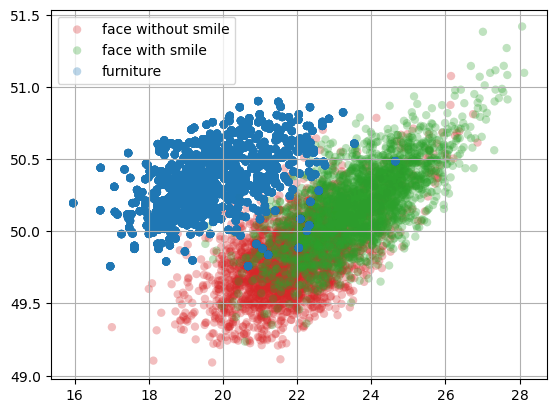

In [21]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo of {item}." if i == 0 else f"This is a photo without {item}." for item in text_list for i in range(2)]
    # text_list_prompt = [f"{item}" if i == 0 else f"not {item}" for item in text_list for i in range(2)]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_smiling.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'smile']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_smiling.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
img_features /= img_features.norm(dim=-1, keepdim=True)
dual_text_features /= dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ dual_text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, len(text_list), 2]), dim=2)
scores = 100 * cs_softmax
dual_scores = scores[:, :, 0]

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = dual_scores[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = dual_scores[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = dual_scores[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without smile')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with smile')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

torch.Size([20000, 2])


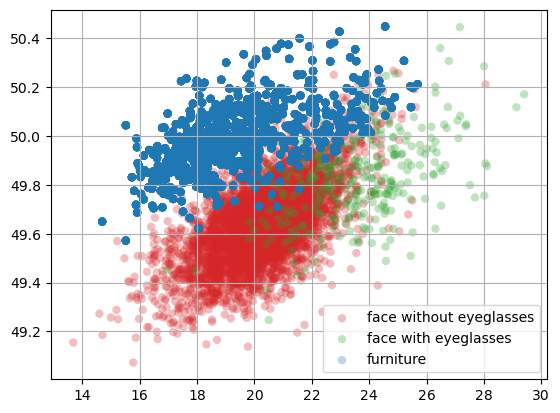

In [22]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo of {item}." if i == 0 else f"This is not a photo of {item}." for item in text_list for i in range(2)]
    # text_list_prompt = [f"{item}" if i == 0 else f"not {item}" for item in text_list for i in range(2)]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'eyeglasses']
text_list_prompt = [f"This is a photo of {item}." for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
img_features /= img_features.norm(dim=-1, keepdim=True)
dual_text_features /= dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ dual_text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, len(text_list), 2]), dim=2)
scores = 100 * cs_softmax
dual_scores = scores[:, :, 0]
print(dual_scores.shape)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = dual_scores[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = dual_scores[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = dual_scores[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without eyeglasses')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with eyeglasses')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

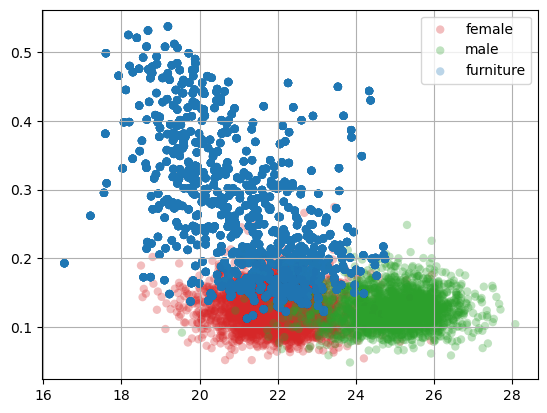

In [29]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    # model, preprocess = clip.load("RN101", device=device)
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo without {item}." for item in text_list] + [f"This is a photo of {item}." for item in text_list]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_male.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'sir']
text_list_prompt = [f"This is a photo of {item}" for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
model, preprocess = clip.load("ViT-B/32", device=device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
# with open('/Users/yifanlu/Desktop/img_features_local.pkl', 'rb') as f:
# with open('/Users/yifanlu/Desktop/img_features_local_modified_dualcoop.pkl', 'rb') as f:
with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_features_local.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_male.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
# normalize features
dual_text_features = dual_text_features / dual_text_features.norm(dim=-1, keepdim=True)  # [44, 512]
image_features_norm = img_features / img_features.norm(dim=1, keepdim=True) # [5000, 512, 50]

# Class-Specific Region Feature Aggregation
# output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
# b, a, p = output.shape  # b 5000 c 44 p 50
# logits_per_patch = output.reshape(b, 2, a // 2, p)  # [5000, 2, 22, 50]
# scores_per_patch = F.softmax(logits_per_patch, dim=1)[:, 1]   # [5000, 22, 50]
# w = F.softmax(output[:, a // 2:], dim=-1)  # [5000, 22, 50]
# # w = F.softmax(scores_per_patch, dim=-1)
# dual_scores = 5 * (scores_per_patch * w).sum(-1)  # [5000, 22]
# print(dual_scores.shape)

# Class-Specific Region Feature Aggregation
output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
b, c, _ = output.shape  # b 5000 c 44
output_half = output[:, c // 2:]  # [5000, 22, 50]
w_half = F.softmax(output_half, dim=-1)  # [5000, 22, 50]
w = torch.cat([w_half, w_half], dim=1)  # [5000, 44, 50]
output = 5 * (output * w).sum(-1)  # [5000, 44]
b, c = output.shape
# convert the shape of logits to [b, 2, num_class]
logits = output.resize(b, 2, c // 2)  # [5000, 2, 22]
Softmax = torch.nn.Softmax(dim=1)
dual_scores = Softmax(logits).cpu()[:, 1]    # [5000, 22]

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 0]
y_0 = dual_scores[img_labels==0][:, 0]
x_1 = original_similarity[img_labels==1][:, 0]
y_1 = dual_scores[img_labels==1][:, 0]
x_2 = original_similarity[img_labels==2][:, 0]
y_2 = dual_scores[img_labels==2][:, 0]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='female')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='male')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

torch.Size([20000, 2])


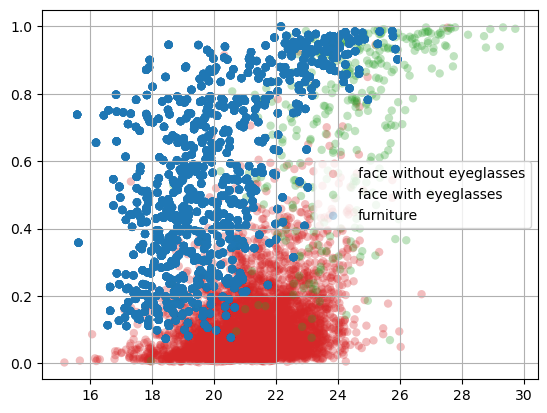

In [33]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("RN101", device=device)
    # model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo without {item}." for item in text_list] + [f"This is a photo of {item}." for item in text_list]
    # text_list_prompt = ["This is a photo of woman.", "This is a photo of person with bare eyes or furniture.", "This is a photo of man.", "This is a photo of person with eyeglasses."]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'eyeglasses']
# text_listopp = ['woman', 'bare eyes']
text_list_prompt = [f"This is a photo of {item}" for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
model, preprocess = clip.load("ViT-B/32", device=device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/img_features_local_modified_dualcoop.pkl', 'rb') as f:
# with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_features_local.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_eyeglasses.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
# normalize features
dual_text_features = dual_text_features / dual_text_features.norm(dim=-1, keepdim=True)  # [44, 512]
image_features_norm = img_features / img_features.norm(dim=1, keepdim=True) # [5000, 512, 50]

# Class-Specific Region Feature Aggregation
# output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
# b, a, p = output.shape  # b 5000 c 44 p 50
# logits_per_patch = output.reshape(b, 2, a // 2, p)  # [5000, 2, 22, 50]
# scores_per_patch = F.softmax(logits_per_patch, dim=1)[:, 1]   # [5000, 22, 50]
# w = F.softmax(output[:, a // 2:], dim=-1)  # [5000, 22, 50]
# # w = F.softmax(scores_per_patch, dim=-1)
# dual_scores = 5 * (scores_per_patch * w).sum(-1)  # [5000, 22]
# print(dual_scores.shape)

# Class-Specific Region Feature Aggregation
output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
b, c, _ = output.shape  # b 5000 c 44
output_half = output[:, c // 2:]  # [5000, 22, 50]
w_half = F.softmax(output_half, dim=-1)  # [5000, 22, 50]
w = torch.cat([w_half, w_half], dim=1)  # [5000, 44, 50]
output = 5 * (output * w).sum(-1)  # [5000, 44]
b, c = output.shape
# convert the shape of logits to [b, 2, num_class]
logits = output.resize(b, 2, c // 2)  # [5000, 2, 22]
Softmax = torch.nn.Softmax(dim=1)
dual_scores = Softmax(logits).cpu()[:, 1]    # [5000, 22]
print(dual_scores.shape)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = dual_scores[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = dual_scores[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = dual_scores[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without eyeglasses')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with eyeglasses')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

torch.Size([20000, 2])


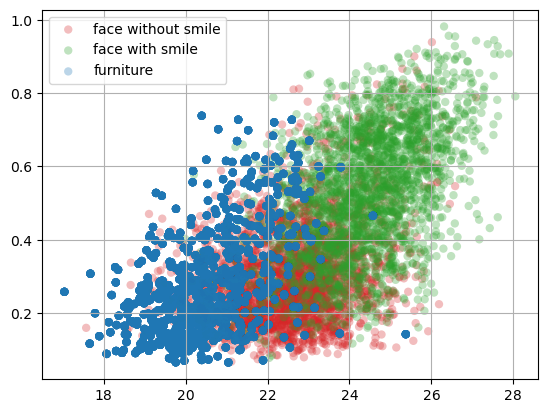

In [81]:
def get_dual_text_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("RN101", device=device)
    text_list_prompt = [f"This is not a photo of {item}." for item in text_list] + [f"This is a photo of {item}." for item in text_list]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).detach()

# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_try.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_smile.pkl', 'rb') as f:
    img_labels = pickle.load(f)

text_list = ['man', 'smile']
text_list_prompt = [f"This is a photo of {item}" for item in text_list]
text = clip.tokenize(text_list_prompt).to(device)
model, preprocess = clip.load("ViT-B/32", device=device)
with torch.no_grad():
    text_features = model.encode_text(text)

dual_text_features = get_dual_text_embedding(text_list)

# <I, T>
img_features = img_features/img_features.norm(dim=-1, keepdim=True)
text_features = text_features/text_features.norm(dim=-1, keepdim=True)
original_similarity = (100 * img_features @ text_features.T)


# read image and text features
with open('/Users/yifanlu/Desktop/img_features_local.pkl', 'rb') as f:
# with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_features_local.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/PycharmProjects/interpretable_evaluation_metrics/img_labels_smile.pkl', 'rb') as f:
    img_labels = pickle.load(f)

# dual scores
# normalize features
dual_text_features = dual_text_features / dual_text_features.norm(dim=-1, keepdim=True)  # [44, 512]
image_features_norm = img_features / img_features.norm(dim=1, keepdim=True) # [5000, 512, 50]

# Class-Specific Region Feature Aggregation
# output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
# b, a, p = output.shape  # b 5000 c 44 p 50
# logits_per_patch = output.reshape(b, 2, a // 2, p)  # [5000, 2, 22, 50]
# scores_per_patch = F.softmax(logits_per_patch, dim=1)[:, 1]   # [5000, 22, 50]
# w = F.softmax(output[:, a // 2:], dim=-1)  # [5000, 22, 50]
# # w = F.softmax(scores_per_patch, dim=-1)
# dual_scores = 5 * (scores_per_patch * w).sum(-1)  # [5000, 22]
# print(dual_scores.shape)

# Class-Specific Region Feature Aggregation
output = 20 * F.conv1d(image_features_norm, dual_text_features[:, :, None])  # input [5000, 512, 50] weight [44, 512, 1] out [5000, 44, 50]
b, c, _ = output.shape  # b 5000 c 44
output_half = output[:, c // 2:]  # [5000, 22, 50]
w_half = F.softmax(output_half, dim=-1)  # [5000, 22, 50]
w = torch.cat([w_half, w_half], dim=1)  # [5000, 44, 50]
output = 5 * (output * w).sum(-1)  # [5000, 44]
b, c = output.shape
# convert the shape of logits to [b, 2, num_class]
logits = output.resize(b, 2, c // 2)  # [5000, 2, 22]
Softmax = torch.nn.Softmax(dim=1)
dual_scores = Softmax(logits).cpu()[:, 1]    # [5000, 22]
print(dual_scores.shape)

# Plotting
fig, ax = plt.subplots()

x_0 = original_similarity[img_labels==0][:, 1]
y_0 = dual_scores[img_labels==0][:, 1]
x_1 = original_similarity[img_labels==1][:, 1]
y_1 = dual_scores[img_labels==1][:, 1]
x_2 = original_similarity[img_labels==2][:, 1]
y_2 = dual_scores[img_labels==2][:, 1]
ax.scatter(x_0, y_0, c='tab:red', alpha=0.3, edgecolors='none', label='face without smile')
ax.scatter(x_1, y_1, c='tab:green', alpha=0.3, edgecolors='none', label='face with smile')
ax.scatter(x_2, y_2, c='tab:blue', alpha=0.3, edgecolors='none', label='furniture')

ax.legend()
ax.grid(True)

plt.show()

## Find most irrelevent attributes
------

In [24]:
def get_embedding(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo of {item}." for item in text_list]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).squeeze().detach().numpy()

# Step 1: Define attributes
relevant_attrs = ['male', 'heavy makeup', 'wearing earrings', 'black hair', 'blond hair', 'wearing eyeglasses', 'wearing hat', 'young', 'with beard', 'smiling',]
irrelevant_attrs = relevant_attrs + ['male', 'dog', 'cat', 'tiger', 'lion', 'bear', 'elephant', 'giraffe', 'zebra',
                    'wolf', 'fox', 'rabbit', 'squirrel', 'eagle', 'penguin', 'dolphin',
                    'whale', 'snake', 'turtle', 'frog', 'butterfly',
                    'sofa', 'chair', 'bed', 'table', 'closet', 'bookshelf', 'mirror', 'nightstand',
                    'carpet', 'television', 'refrigerator', 'washing machine', 'microwave oven', 'bowl',
                    'plate', 'cup', 'curtain', 'pillow', 'clock', 'computer']

# Step 2: Get embeddings
E_relevant = get_embedding(relevant_attrs)
E_irrelevant = get_embedding(irrelevant_attrs)

# Step 3: Compute centroids
m_rel = E_relevant.mean(axis=0)
m_irr = E_irrelevant.mean(axis=0)

# Step 4: Direction vector pointing from irrelevant space to relevant space
v = normalize((m_rel - m_irr).reshape(1, -1))[0]

# Step 5: Project irrelevant attributes onto vector v
# If dot(e - m_rel, v) < 0, it's on the opposite side of the relevant cluster
projections = np.dot(m_rel, (E_irrelevant - m_rel).T)

 
filtered_attr = []
for a, r in zip(irrelevant_attrs, projections):
    print(a,r)
    if r < -17:
        filtered_attr.append(a)
print(filtered_attr)

male 12.110569
heavy makeup -4.1243167
wearing earrings -6.3515635
black hair -7.592185
blond hair -9.19618
wearing eyeglasses -3.5944135
wearing hat -8.293781
young 12.726604
with beard 10.005774
smiling 4.309469
male 12.110569
dog 2.4814587
cat -3.5532627
tiger -10.134629
lion -8.126193
bear 3.150833
elephant -13.424713
giraffe -28.49674
zebra -28.405468
wolf -2.8097568
fox -6.721948
rabbit -10.317417
squirrel -15.030561
eagle -12.563993
penguin -20.769814
dolphin -16.751099
whale -15.06109
snake -10.763397
turtle -13.637648
frog -12.033452
butterfly -10.678513
sofa -24.75941
chair -21.338367
bed -11.902296
table -14.614062
closet -13.578785
bookshelf -10.057935
mirror -15.850151
nightstand -22.877113
carpet -24.64038
television 1.728848
refrigerator -24.531294
washing machine -20.13952
microwave oven -28.680496
bowl -10.467114
plate -7.0278044
cup -7.95152
curtain -22.853184
pillow -18.486992
clock -5.632072
computer -3.0083444
['giraffe', 'zebra', 'penguin', 'sofa', 'chair', 'night

In [25]:
def get_embedding_neg(text_list):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    text_list_prompt = [f"This is a photo without {item}." for item in text_list]
    text = clip.tokenize(text_list_prompt).to(device)
    return model.encode_text(text).squeeze().detach().numpy()

# Step 2: Get embeddings
E_relevant = get_embedding_neg(relevant_attrs)

In [26]:
E_irrelevant_new = get_embedding(filtered_attr)
E_all = np.concat((E_relevant, E_irrelevant_new),0)

m_all = E_all.mean(axis=0)
projections_all = np.dot(m_all, (E_all-m_all).T)

for a, r in zip( relevant_attrs + filtered_attr, projections_all):
    print(a,r)

male 21.967272
heavy makeup 15.438545
wearing earrings 22.460987
black hair 19.522337
blond hair 24.647797
wearing eyeglasses 23.049824
wearing hat 20.455338
young 18.658705
with beard 20.779785
smiling 19.937967
giraffe -22.13107
zebra -21.872213
penguin -15.144212
sofa -16.987637
chair -15.2219715
nightstand -16.074274
carpet -18.770157
refrigerator -17.007956
washing machine -13.309227
microwave oven -21.982431
curtain -16.175722
pillow -12.241634


Plotting TSNE image


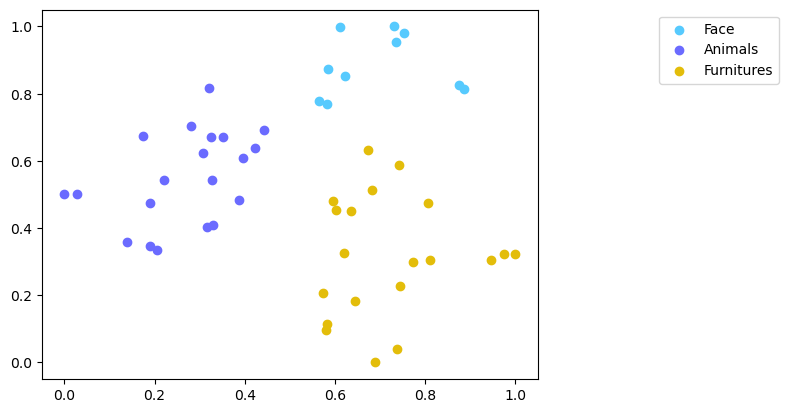

In [27]:
text_list = ['male', 'heavy makeup', 'wearing earrings', 'black hair', 'blond hair',
             'wearing eyeglasses', 'wearing hat', 'young', 'with beard', 'smiling',
             'dog', 'cat', 'tiger', 'lion', 'bear', 'elephant', 'giraffe', 'zebra',
             'wolf', 'fox', 'rabbit', 'squirrel', 'eagle', 'penguin', 'dolphin',
             'whale', 'snake', 'turtle', 'frog', 'butterfly',
             'sofa', 'chair', 'bed', 'table', 'closet', 'bookshelf', 'mirror', 'nightstand',
             'carpet', 'television', 'refrigerator', 'washing machine', 'microwave oven', 'bowl',
             'plate', 'cup', 'curtain', 'pillow', 'clock', 'computer']
text_features = get_embedding(text_list)
text_features_labels = np.concatenate([np.zeros(10), np.ones(20), 2*np.ones(20)])
# extract x and y coordinates representing the positions of the images on T-SNE plot
tsne = TSNE(n_components=2).fit_transform(text_features)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, text_features_labels, ['Face', 'Animals', 'Furnitures'])

--------

(20022, 512)
(20022,)
Plotting TSNE image


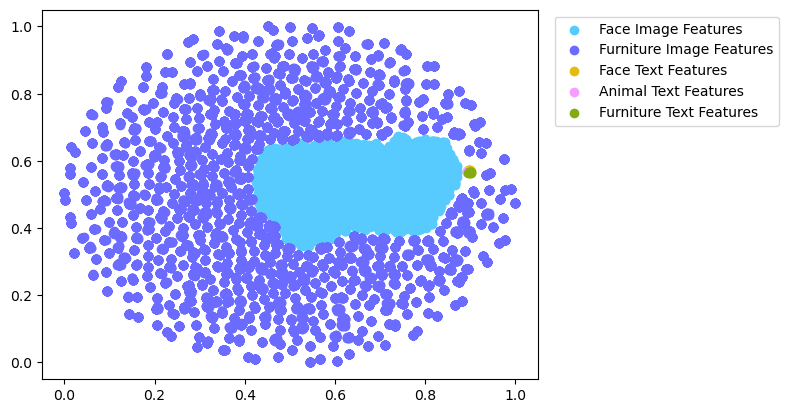

In [28]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# combine image and text features to plot scatter plot
img_text_features = np.concatenate((img_features, text_features), axis=0)
img_text_features_labels = np.concatenate((labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)

# extract x and y coordinates representing the positions of the images on T-SNE plot
tsne = TSNE(n_components=2).fit_transform(img_text_features)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Face Image Features', 'Furniture Image Features', 'Face Text Features', 'Animal Text Features', 'Furniture Text Features'])

Plotting TSNE image


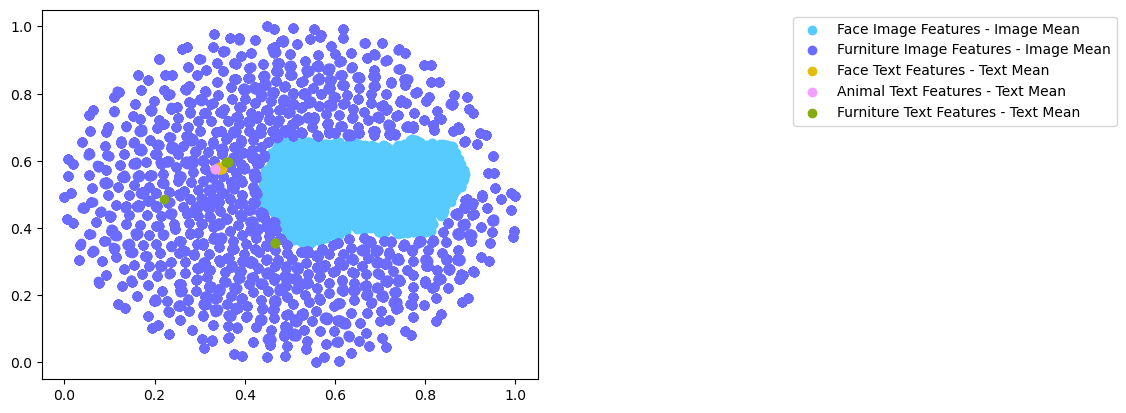

In [29]:
# subtraction of mean value
img_features_minus_mean = img_features - img_features.mean(axis=0)
text_features_minus_mean = text_features - text_features.mean(axis=0)
img_text_features = np.concatenate((img_features_minus_mean, text_features_minus_mean), axis=0)
img_text_features_labels = np.concatenate((labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)

# extract x and y coordinates representing the positions of the images on T-SNE plot
tsne = TSNE(n_components=2).fit_transform(img_text_features)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Face Image Features - Image Mean', 'Furniture Image Features - Image Mean', 'Face Text Features - Text Mean', 'Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean'])

(20022, 2)
(20022,)
Plotting TSNE image


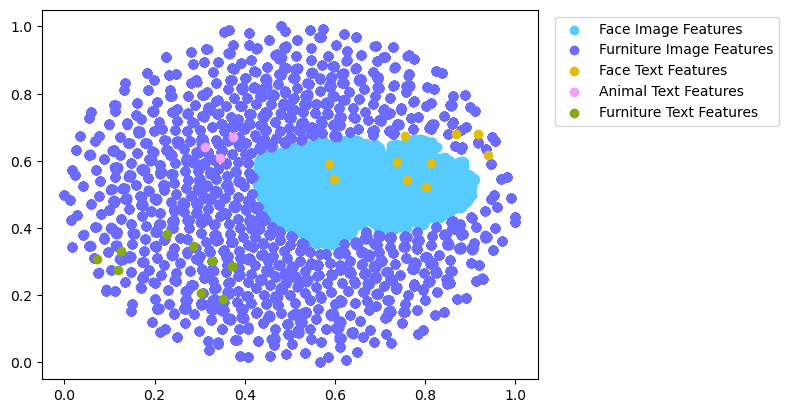

In [35]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# T-SNE reduce dimensions
tsne_img = TSNE(n_components=2).fit_transform(img_features)
tsne_text = TSNE(n_components=2, perplexity=5).fit_transform(text_features)

# combine image and text features to plot scatter plot
tsne = np.concatenate((tsne_img, tsne_text), axis=0)
img_text_features_labels = np.concatenate((labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(tsne.shape)
print(img_text_features_labels.shape)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Face Image Features', 'Furniture Image Features', 'Face Text Features', 'Animal Text Features', 'Furniture Text Features'])

(20022, 2)
(20022,)
Plotting TSNE image


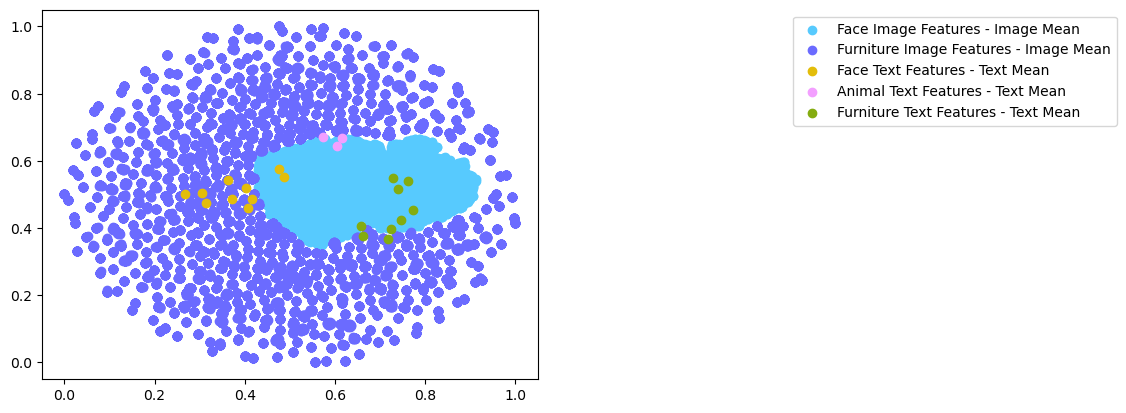

In [36]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# T-SNE reduce dimensions
tsne_img = TSNE(n_components=2).fit_transform((img_features - img_features.mean(axis=0)))
tsne_text = TSNE(n_components=2, perplexity=5).fit_transform((text_features - text_features.mean(axis=0)))

# combine image and text features to plot scatter plot
tsne = np.concatenate((tsne_img, tsne_text), axis=0)
img_text_features_labels = np.concatenate((labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(tsne.shape)
print(img_text_features_labels.shape)

tx = tsne[:, 0]
ty = tsne[:, 1] 
tx = scale_to_01_range(tx)
ty = scale_to_01_range(ty)

visualize_tsne_points(tx, ty, img_text_features_labels, ['Face Image Features - Image Mean', 'Furniture Image Features - Image Mean', 'Face Text Features - Text Mean','Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean'])

(20522, 512)
(20522,)
Plotting TSNE image


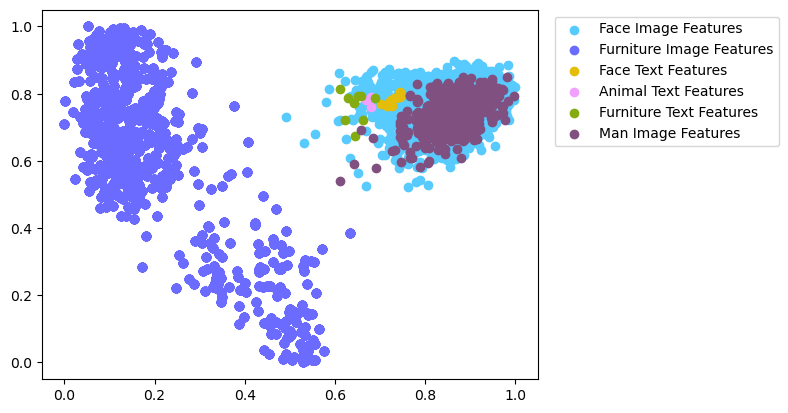

In [38]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# combine image and text features to plot scatter plot
img_text_features = np.concatenate((man_img_features, img_features, text_features), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]),labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)


# PCA dimension reduction
pca = PCA(n_components=2).fit_transform(img_text_features)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features', 'Furniture Image Features', 'Face Text Features', 'Animal Text Features', 'Furniture Text Features', 'Man Image Features'])

Plotting TSNE image


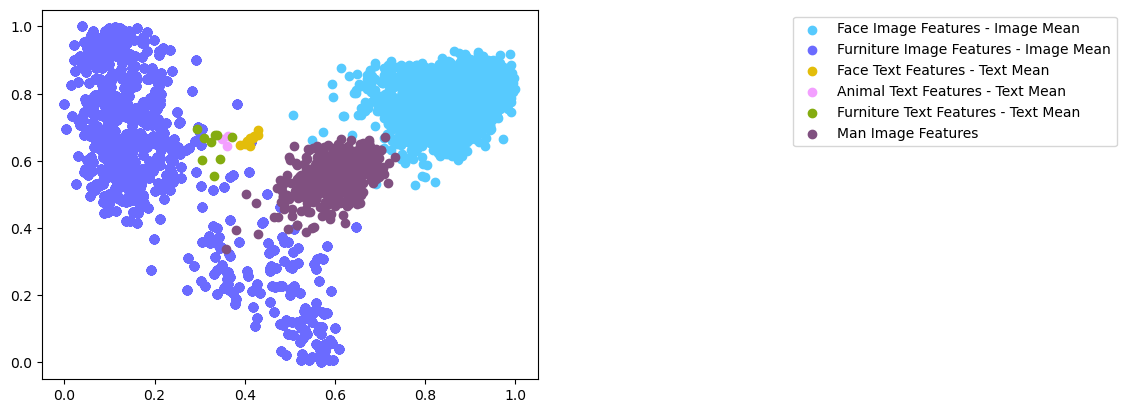

In [39]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

img_features_minus_mean = img_features - img_features.mean(axis=0)
text_features_minus_mean = text_features - text_features.mean(axis=0)
img_text_features = np.concatenate((man_img_features, img_features_minus_mean, text_features_minus_mean), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]),labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)

# PCA dimension reduction
pca = PCA(n_components=2).fit_transform(img_text_features)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features - Image Mean', 'Furniture Image Features - Image Mean', 'Face Text Features - Text Mean', 'Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean', 'Man Image Features'])

(20522, 512)
(20522,)
Plotting TSNE image


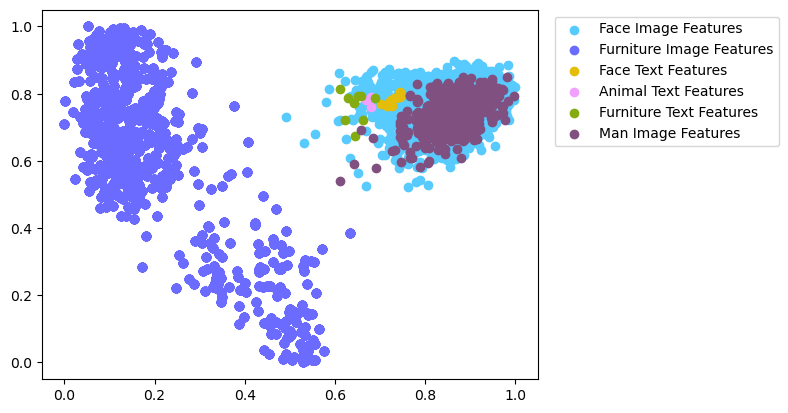

In [40]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# combine image and text features to plot scatter plot
img_text_features = np.concatenate((man_img_features, img_features, text_features), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]), labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)


# PCA dimension reduction
pca = PCA(n_components=2).fit_transform(img_text_features)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features', 'Furniture Image Features', 'Face Text Features', 'Animal Text Features', 'Furniture Text Features', 'Man Image Features'])

Plotting TSNE image


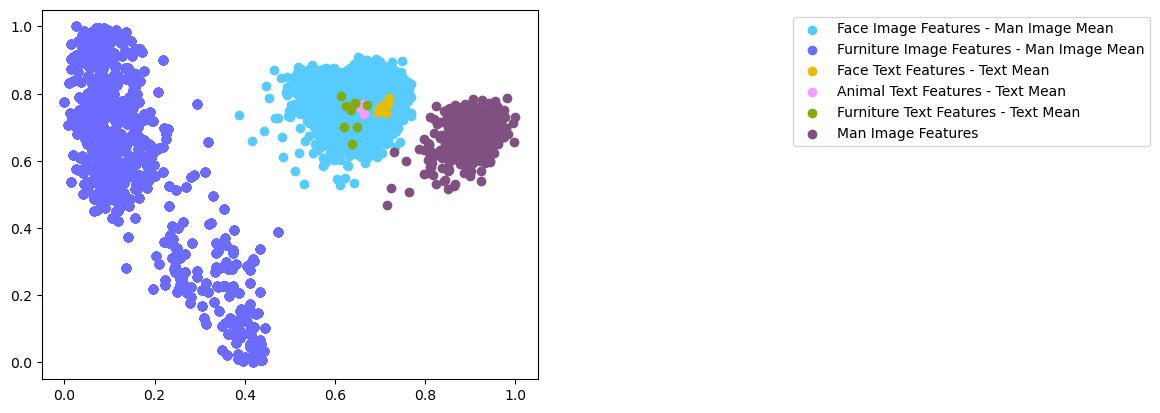

In [41]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

img_features_minus_mean = img_features - man_img_features.mean(axis=0)
text_features_minus_mean = text_features - text_features.mean(axis=0)
img_text_features = np.concatenate((man_img_features, img_features_minus_mean, text_features_minus_mean), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]), labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)

# PCA dimension reduction
pca = PCA(n_components=2).fit_transform(img_text_features)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features - Man Image Mean', 'Furniture Image Features - Man Image Mean', 'Face Text Features - Text Mean', 'Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean', 'Man Image Features'])

(20522, 512)
(20522,)
Plotting TSNE image


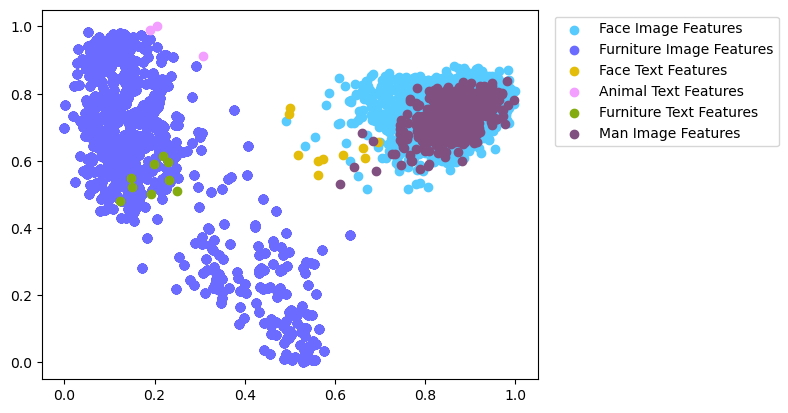

In [42]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# PCA dimension reduction
pca_img = PCA(n_components=2).fit_transform(np.concatenate((man_img_features, img_features), axis=0))
pca_text = PCA(n_components=2).fit_transform(text_features)

# combine image and text features to plot scatter plot
pca = np.concatenate((pca_img, pca_text), axis=0)
img_text_features_labels = np.concatenate((5* torch.ones(man_img_features.shape[0]), labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)

px = pca[:, 0]
py = pca[:, 1]
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features', 'Furniture Image Features', 'Face Text Features', 'Animal Text Features', 'Furniture Text Features', 'Man Image Features'])

(20522, 512)
(20522,)
Plotting TSNE image


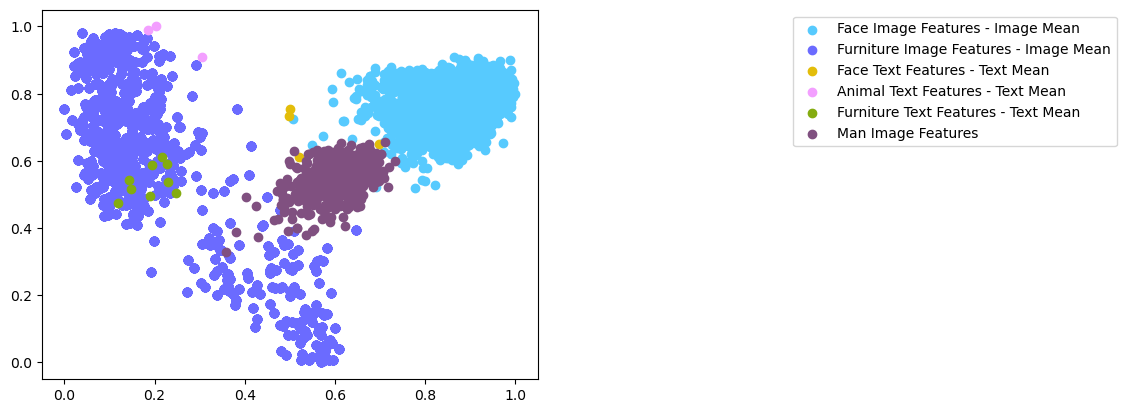

In [43]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# PCA dimension reduction
pca_img = PCA(n_components=2).fit_transform(np.concatenate((man_img_features, img_features-img_features.mean(axis=0)), axis=0))
pca_text = PCA(n_components=2).fit_transform((text_features-text_features.mean(axis=0)))

# combine image and text features to plot scatter plot
pca = np.concatenate((pca_img, pca_text), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]), labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features - Image Mean', 'Furniture Image Features - Image Mean', 'Face Text Features - Text Mean', 'Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean', 'Man Image Features'])

(20522, 512)
(20522,)
Plotting TSNE image


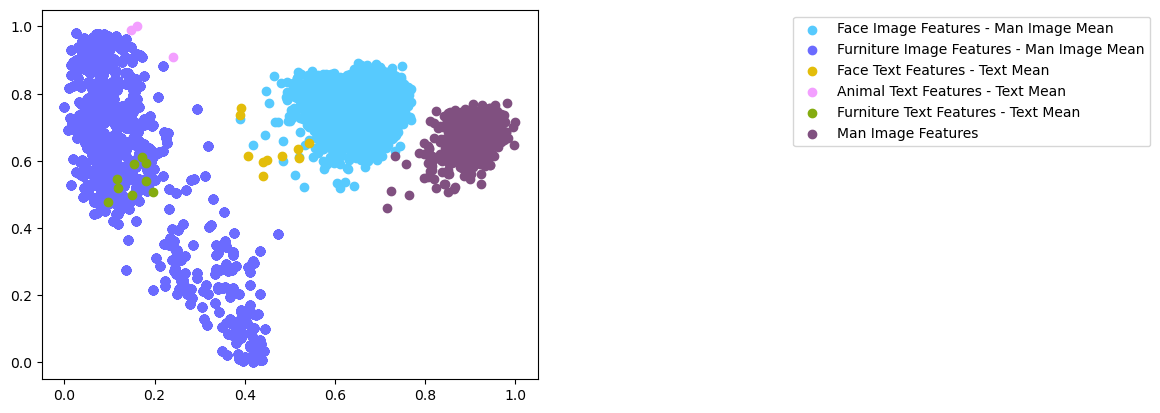

In [44]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features.pkl', 'rb') as f:
    img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/img_labels.pkl', 'rb') as f:
    labels = pickle.load(f).cpu().numpy()

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    text_features = pickle.load(f).cpu().numpy()

# PCA dimension reduction
pca_img = PCA(n_components=2).fit_transform(np.concatenate((man_img_features, img_features-man_img_features.mean(axis=0)), axis=0))
pca_text = PCA(n_components=2).fit_transform((text_features-text_features.mean(axis=0)))

# combine image and text features to plot scatter plot
pca = np.concatenate((pca_img, pca_text), axis=0)
img_text_features_labels = np.concatenate((5*torch.ones(man_img_features.shape[0]), labels, 2*torch.ones(10), 3*torch.ones(3), 4* torch.ones(9)), axis=0)
print(img_text_features.shape)
print(img_text_features_labels.shape)

px = pca[:, 0]
py = pca[:, 1] 
px = scale_to_01_range(px)
py = scale_to_01_range(py)

visualize_tsne_points(px, py, img_text_features_labels, ['Face Image Features - Man Image Mean', 'Furniture Image Features - Man Image Mean', 'Face Text Features - Text Mean', 'Animal Text Features - Text Mean', 'Furniture Text Features - Text Mean', 'Man Image Features'])

------

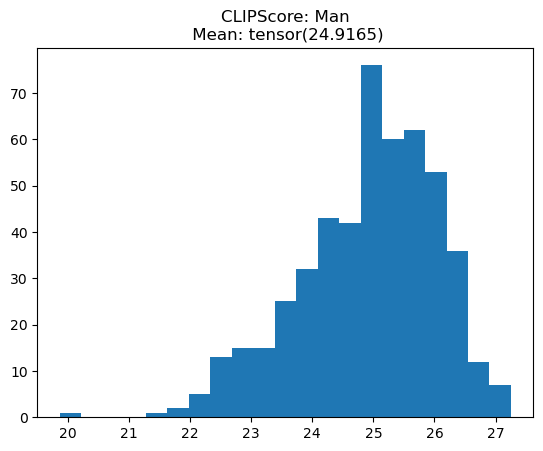

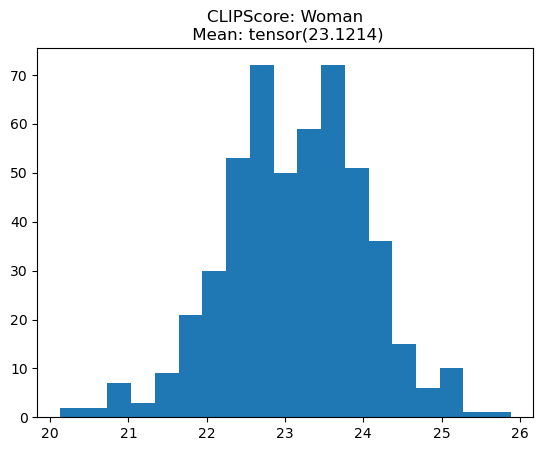

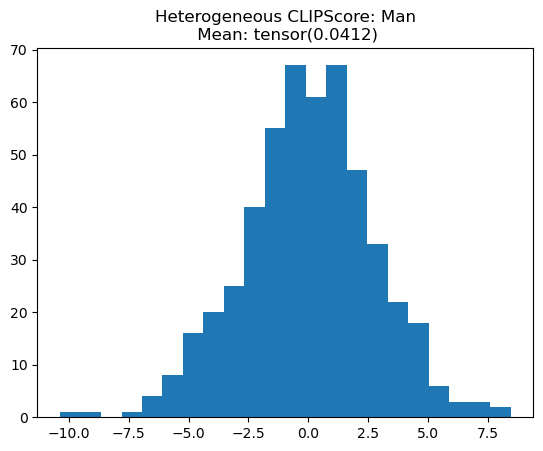

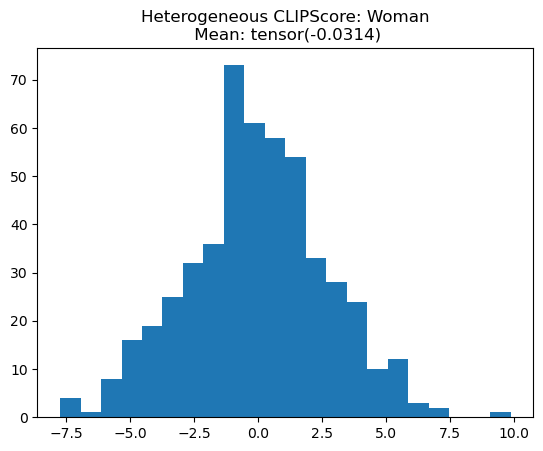

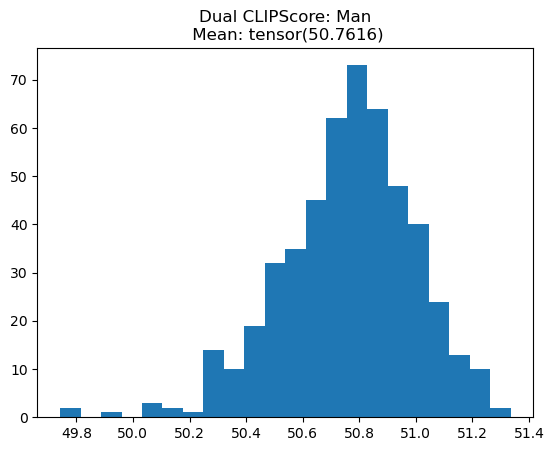

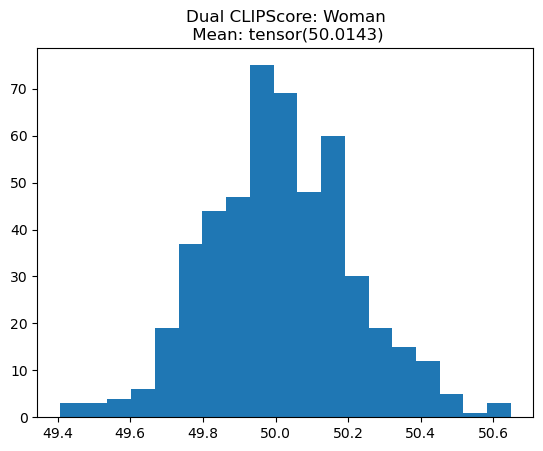

In [67]:
# read image and text features
with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_man.pkl', 'rb') as f:
    man_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/img_features_woman.pkl', 'rb') as f:
    woman_img_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_HCS.pkl', 'rb') as f:
    original_text_features = pickle.load(f)

with open('/Users/yifanlu/Desktop/vit32-tmp/text_features_celebA_22_USER_dualCS.pkl', 'rb') as f:
    dual_text_features = pickle.load(f)

# <I, T>
img_features = man_img_features/man_img_features.norm(dim=-1, keepdim=True)
text_features = original_text_features/original_text_features.norm(dim=-1, keepdim=True)
man_original_similarity = (100 * img_features @ text_features.T)

# <I, T>
img_features = woman_img_features/woman_img_features.norm(dim=-1, keepdim=True)
text_features = original_text_features/original_text_features.norm(dim=-1, keepdim=True)
woman_original_similarity = (100 * img_features @ text_features.T)

# <I-I_mean, T-T_mean>
img_features = man_img_features - man_img_features.mean(axis=0)
text_features = original_text_features - original_text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
man_similarity_minus_mean = (100 * img_features @ text_features.T)

# <I-I_mean, T-T_mean>
img_features = woman_img_features - woman_img_features.mean(axis=0)
text_features = original_text_features - original_text_features.mean(axis=0)
img_features /= img_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
woman_similarity_minus_mean = (100 * img_features @ text_features.T)

# dual: man
num_attributs = dual_text_features.shape[0] // 2
img_features = man_img_features/man_img_features.norm(dim=-1, keepdim=True)
text_features = dual_text_features/dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, num_attributs, 2]), dim=2)
scores = 100 * cs_softmax
man_dual_scores = scores[:, :, 0]

# dual: woman
num_attributs = text_features.shape[0] // 2
img_features = woman_img_features/woman_img_features.norm(dim=-1, keepdim=True)
text_features = dual_text_features/dual_text_features.norm(dim=-1, keepdim=True)
cs = img_features @ text_features.T
cs_softmax = torch.softmax(cs.reshape([-1, num_attributs, 2]), dim=2)
scores = 100 * cs_softmax
woman_dual_scores = scores[:, :, 0]


plt.hist(man_original_similarity[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("CLIPScore: Man"+ '\n Mean: ' + str(man_original_similarity[:,0].mean()))
plt.show()

plt.hist(woman_original_similarity[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("CLIPScore: Woman"+ '\n Mean: ' + str(woman_original_similarity[:,0].mean()))
plt.show()

plt.hist(man_similarity_minus_mean[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("Heterogeneous CLIPScore: Man" + '\n Mean: ' + str(man_similarity_minus_mean[:,0].mean()))
plt.show()

plt.hist(woman_similarity_minus_mean[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("Heterogeneous CLIPScore: Woman"+ '\n Mean: ' + str(woman_similarity_minus_mean[:,0].mean()))
plt.show()

plt.hist(man_dual_scores[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("Dual CLIPScore: Man" + '\n Mean: ' + str(man_dual_scores[:,0].mean()))
plt.show()

plt.hist(woman_dual_scores[:,0], bins='auto')  # arguments are passed to np.histogram
plt.title("Dual CLIPScore: Woman"+ '\n Mean: ' + str(woman_dual_scores[:,0].mean()))
plt.show()